# 자연어 처리 6일차 (3) — 전이 학습 : 사전 학습된 BERT 를 네이버 영화 리뷰로 미세 조정 (Trainer)

수업 필기 `nlp_실습10_전이학습` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `자연어처리` 교재v1 **p.108 · 112~113** — 사전 학습 · 전이 학습 · 미세 조정 · 텍스트 분류 실습 순서 1~8)

```
사전 학습 (pre-training)   : 대량의 글로 MLM · NSP → klue/bert-base · bert-base-multilingual-cased   (남이 해 둔 것)
미세 조정 (fine-tuning)    : 그 가중치를 출발점으로 + 분류층(768 → 2) → 네이버 영화 리뷰 감성 학습   (이 노트)
추론 (inference)           : 학습된 모델로 새 리뷰 예측 (가중치 고정)
```

- 원본은 Colab **GPU** 로 학습 15만 개 · 1 에폭(모델당 약 16~18분)을 돌렸다. 이 노트는 **GPU 가 있으면 원본과 같은 전체 데이터**, 없으면(CPU) **일부만 뽑아** 같은 코드를 돌린다 (§0 `FULL`).
- 원본에서 고친 부분은 **📝 고친 부분** 으로 적었습니다.

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `transformers` | `AutoTokenizer` · `BertForSequenceClassification` · `TrainingArguments` · `Trainer` · `pipeline` | Colab 기본 포함 · 로컬은 `pip install transformers` |
| `accelerate` | `Trainer` 가 내부에서 사용 | Colab 기본 포함 · 로컬은 `pip install accelerate` |
| `torch` · `scikit-learn` · `pandas` | 학습 · 정확도 · 데이터 | Colab 기본 포함 |

**데이터** : 네이버 영화 리뷰(NSMC) `ratings_train.txt`(15만) · `ratings_test.txt`(5만) — 노트북 폴더에 있으면 그것을, 없으면 원 저장소([e9t/nsmc](https://github.com/e9t/nsmc))에서 바로 읽는다. 같은 파일이 [Day 039 폴더](../../2026-11-03/lecture/)에도 있다.

**모델** (첫 실행 때 자동 다운로드 → **인터넷 필요**) : `google-bert/bert-base-multilingual-cased`(약 714MB) · `klue/bert-base`(약 445MB)

**실행 순서 · 시간**
1. Colab : **[런타임] → [런타임 유형 변경] → T4 GPU** → 맨 위부터 **[모두 실행]** → 전체 데이터로 모델당 약 15~20분
2. CPU : 그대로 **[모두 실행]** → 학습 3,000개 · 평가 2,000개만 뽑아 모델당 약 7~8분 (이 노트의 저장된 결과가 이 경우)

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q transformers accelerate torch scikit-learn pandas

In [2]:
import warnings, os
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'      # 다운로드 진행 막대 숨기기
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                      # 'LOAD REPORT' 같은 안내 줄 숨기기 (아래 셀에서 직접 확인)
hf_logging.disable_progress_bar()
from huggingface_hub.utils import logging as hub_logging
hub_logging.set_verbosity_error()                     # 'unauthenticated requests' 안내 숨기기 (로그인 없이도 공개 모델은 받아진다)

In [3]:
import numpy as np
import pandas as pd
import torch
from transformers import set_seed
set_seed(42)

FULL = torch.cuda.is_available()           # GPU 면 전체 데이터, CPU 면 일부만
N_TRAIN, N_VAL, N_TEST = (None, None, None) if FULL else (3000, 500, 2000)
print('GPU 사용 :', FULL, '| 학습 · 검증 · 평가 개수 :', 'all' if FULL else (N_TRAIN, N_VAL, N_TEST))

GPU 사용 : False | 학습 · 검증 · 평가 개수 : (3000, 500, 2000)


> **📝 고친 부분 (원본 cell 1~3)** 빈 셀 `# 무료 gpu 설정` → 메뉴에서 켜는 방법을 위에 적고, GPU 유무로 데이터 크기를 자동으로 정한다. `drive.mount` 대신 노트북 폴더 → 원 저장소 순서로 데이터를 찾는다.

## 1. 학습용 · 검증용 · 평가용 데이터 (교재 p.113 순서 1)

In [4]:
def load_nsmc(name):
    for path in [name, f'data/{name}', f'../../2026-11-03/lecture/{name}']:
        if os.path.exists(path):
            return pd.read_csv(path, sep='\t')
    return pd.read_csv(f'https://raw.githubusercontent.com/e9t/nsmc/master/{name}', sep='\t')

df_train = load_nsmc('ratings_train.txt')
df_test = load_nsmc('ratings_test.txt')
print('학습', df_train.shape, '결측', df_train['document'].isnull().sum(), '| 평가', df_test.shape, '결측', df_test['document'].isnull().sum())
df_train1 = df_train.dropna(ignore_index=True)
df_test1 = df_test.dropna(ignore_index=True)
print('결측 제거 후 :', len(df_train1), '·', len(df_test1), '| 긍정 비율', df_train1['label'].mean().round(3), df_test1['label'].mean().round(3))
df_train1.head(3)

학습 (150000, 3) 결측 5 | 평가 (50000, 3) 결측 3
결측 제거 후 : 149995 · 49997 | 긍정 비율 0.499 0.503


,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(df_train1['document'].tolist(), df_train1['label'].tolist(),
                                                  test_size=0.2, random_state=0, stratify=df_train1['label'])
X_test, y_test = df_test1['document'].tolist(), df_test1['label'].tolist()
print('원본과 같은 나눔 — 학습', len(X_train), '· 검증', len(X_val), '· 평가', len(X_test))

def take(X, y, n, seed=0):                 # CPU 일 때만 앞에서 n 개를 무작위로
    if n is None:
        return X, y
    idx = np.random.RandomState(seed).permutation(len(X))[:n]
    return [X[i] for i in idx], [y[i] for i in idx]

X_train, y_train = take(X_train, y_train, N_TRAIN)
X_val, y_val = take(X_val, y_val, N_VAL)
X_test, y_test = take(X_test, y_test, N_TEST)
print('이번 실행 — 학습', len(X_train), '· 검증', len(X_val), '· 평가', len(X_test), '| 학습 긍정 비율', round(np.mean(y_train), 3))

원본과 같은 나눔 — 학습 119996 · 검증 29999 · 평가 49997
이번 실행 — 학습 3000 · 검증 500 · 평가 2000 | 학습 긍정 비율 0.508


> **📝 고친 부분 (원본 cell 5~9)** 15만 개 리스트 · 데이터프레임 전체를 `display` → 개수 · 비율 · 앞 몇 줄만. 오타 `임폴트` → 임포트.

## 2. 토크나이저 비교 — 다국어 BERT vs 한국어 KLUE BERT

In [6]:
from transformers import AutoTokenizer
multi_name, klue_name = 'google-bert/bert-base-multilingual-cased', 'klue/bert-base'
multi_tokenizer = AutoTokenizer.from_pretrained(multi_name)
klue_tokenizer = AutoTokenizer.from_pretrained(klue_name)

text = '너와 함께한 시간 모두 눈부셨다. 날이 좋아서 날이 좋지 않아서 날이 적당해서 모든 날이 좋았다.'
for tok, name in [(multi_tokenizer, 'Multilingual BERT'), (klue_tokenizer, 'KLUE BERT')]:
    t = tok.tokenize(text)
    print(f'[{name}] 사전 {tok.vocab_size:,}개 · 토큰 {len(t)}개\n{t}\n')

[Multilingual BERT] 사전 119,547개 · 토큰 35개
['너', '##와', '함께', '##한', '시', '##간', '모두', '눈', '##부', '##셨', '##다', '.', '날', '##이', '좋', '##아', '##서', '날', '##이', '좋', '##지', '않', '##아', '##서', '날', '##이', '적', '##당', '##해서', '모든', '날', '##이', '좋', '##았다', '.']

[KLUE BERT] 사전 32,000개 · 토큰 32개
['너', '##와', '함께', '##한', '시간', '모두', '눈부', '##셨', '##다', '.', '날', '##이', '좋아', '##서', '날', '##이', '좋', '##지', '않', '##아', '##서', '날', '##이', '적당', '##해서', '모든', '날', '##이', '좋', '##았', '##다', '.']



In [7]:
# 리뷰별 토큰 수 — tokenize() 는 [CLS] · [SEP] 를 세지 않는다
sample = df_train1['document'].sample(20000, random_state=0).tolist()      # 15만 개 전체 대신 2만 개로 통계
len_multi = [len(multi_tokenizer.tokenize(r)) for r in sample]
len_klue = [len(klue_tokenizer.tokenize(r)) for r in sample]
p90_multi, p90_klue = np.percentile(len_multi, 90), np.percentile(len_klue, 90)
print(f'90% 분위수 — 다국어 {p90_multi:.0f} · KLUE {p90_klue:.0f} (원본 15만 개 기준 50 · 42)')
print(f'평균 토큰 수 — 다국어 {np.mean(len_multi):.1f} · KLUE {np.mean(len_klue):.1f}')
print(f'[UNK] 비율 — 다국어 {np.mean([multi_tokenizer.unk_token in multi_tokenizer.tokenize(r) for r in sample[:3000]]):.1%} · '
      f'KLUE {np.mean([klue_tokenizer.unk_token in klue_tokenizer.tokenize(r) for r in sample[:3000]]):.1%} (리뷰에 [UNK] 가 하나라도 있는 비율)')

MAX_MULTI, MAX_KLUE = int(p90_multi) + 2, int(p90_klue) + 2                  # + [CLS] · [SEP]
print('max_length :', MAX_MULTI, MAX_KLUE)

90% 분위수 — 다국어 51 · KLUE 43 (원본 15만 개 기준 50 · 42)
평균 토큰 수 — 다국어 24.1 · KLUE 20.4


[UNK] 비율 — 다국어 29.2% · KLUE 5.1% (리뷰에 [UNK] 가 하나라도 있는 비율)
max_length : 53 45


- 한국어 전용 사전(KLUE, 32,000개)이 `시간 · 눈부 · 좋아 · 적당` 처럼 더 큰 조각으로 끊어 **같은 리뷰를 더 적은 토큰**으로 표현한다. 다국어 BERT(119,547개)는 104개 언어가 사전을 나눠 써서 한국어가 잘게 쪼개진다(`시 ##간`).
- 더 큰 차이는 **[UNK]** — 다국어 사전에는 `ㅋ · ㅠ · ㅎ` 같은 자음 · 모음 글자와 `밌` 같은 글자가 없어서 `ㅋㅋㅋ 재밌다 ㅠㅠ` 가 `[UNK] [UNK] [UNK]` 가 된다(KLUE 는 `ㅋㅋㅋ · 재밌 · ##다 · ㅠㅠ`). 그 글자가 들어간 단어 전체가 [UNK] 하나로 바뀌어 뜻이 사라진다 — 영화 리뷰의 약 30% 에서 일어난다.

> **📝 고친 부분 (원본 cell 16~21)**
> - `tokenize()` 는 `[CLS]` · `[SEP]` 를 넣지 않는다 → 90% 분위수(50 · 42)를 그대로 `max_length` 로 쓰면 실제 내용은 48 · 40 토큰만 들어간다 → **분위수 + 2**
> - 리뷰 15만 개의 토큰 수 리스트를 통째로 출력 → 통계만
> - 오타 `토크의 수` · `np.percentilte()` → 토큰의 수 · `np.percentile()`

## 3. 모델 입력 — `input_ids` · `attention_mask` · `token_type_ids` (교재 p.113 순서 2~3)

In [8]:
def encode(tok, X, max_len):
    return tok(X, truncation=True, padding='max_length', max_length=max_len, return_tensors='pt')

ex = encode(klue_tokenizer, ['아 더빙.. 진짜 짜증나네요 목소리'], 12)
for k, v in ex.items():
    print(f'{k:15s}', v[0].tolist())
print('토큰 :', klue_tokenizer.convert_ids_to_tokens(ex['input_ids'][0]))

input_ids       [2, 1376, 831, 2604, 18, 18, 4229, 9801, 2075, 2203, 2182, 3]
token_type_ids  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
토큰 : ['[CLS]', '아', '더', '##빙', '.', '.', '진짜', '짜증', '##나', '##네', '##요', '[SEP]']


In [9]:
class ClassificationDataset(torch.utils.data.Dataset):
    """토크나이저 결과(inputs) + 정답(labels) → Trainer 가 읽는 딕셔너리"""
    def __init__(self, inputs, labels):
        self.inputs, self.labels = inputs, labels
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.inputs.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    def __len__(self):
        return len(self.labels)

def make_sets(tok, max_len):
    return [ClassificationDataset(encode(tok, X, max_len), y) for X, y in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]]

multi_train, multi_val, multi_test = make_sets(multi_tokenizer, MAX_MULTI)
klue_train, klue_val, klue_test = make_sets(klue_tokenizer, MAX_KLUE)
print('KLUE 학습용 :', len(klue_train), '개 · 첫 항목 키', list(klue_train[0].keys()))

KLUE 학습용 : 3000 개 · 첫 항목 키 ['input_ids', 'token_type_ids', 'attention_mask', 'labels']


> **📝 고친 부분 (원본 cell 20~24)**
> - `padding=True` 는 **넣은 데이터 중 가장 긴 것**에 맞춘다(여기선 결국 max_length) → 뜻이 분명하게 `padding='max_length'`
> - `val[idx].clone().detach()` → 이미 텐서라 인덱싱만으로 충분
> - KLUE 데이터셋을 만들고 출력 문구가 '**BERT 다국어 모델** 학습용 데이터' (복사 · 붙여넣기 흔적) · 객체 주소(`<__main__…at 0x…>`)만 출력 → 개수 · 키를 출력

## 4. 미세 조정 — `BertForSequenceClassification` + `Trainer` (교재 p.113 순서 4~8)

In [10]:
from transformers import BertForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score

def compute_metrics(pred):
    return {'accuracy': accuracy_score(pred.label_ids, pred.predictions.argmax(-1))}

id2label, label2id = {0: 'negative', 1: 'positive'}, {'negative': 0, 'positive': 1}

def finetune(model_name, tok, train_ds, val_ds, out_dir):
    model = BertForSequenceClassification.from_pretrained(model_name, num_labels=2, id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=1,
        per_device_train_batch_size=128 if FULL else 16,
        per_device_eval_batch_size=64,
        learning_rate=5e-5,                  # BERT 논문 권장 범위 5e-5 · 3e-5 · 2e-5
        weight_decay=0.01,
        warmup_steps=0.1,                    # 처음 10% 는 학습률을 서서히 올림 (transformers 5 : 0~1 실수 = 비율, 4.x 는 warmup_ratio=0.1)
        eval_strategy='epoch',
        save_strategy='no',                  # 1 에폭 — 중간 저장 · 최고 모델 다시 불러오기 불필요
        logging_steps=25,
        report_to='none',
        seed=42,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      processing_class=tok, compute_metrics=compute_metrics)
    return model, trainer

In [11]:
# 미세 조정 전 : 분류층(768 → 2)은 새로 만든 무작위 가중치
m = BertForSequenceClassification.from_pretrained(klue_name, num_labels=2)
print('분류층 :', m.classifier, '| BERT 본체 가중치', f'{sum(p.numel() for p in m.bert.parameters()):,}', '개는 사전 학습 값 그대로')
before = Trainer(model=m, args=TrainingArguments(output_dir='tmp_eval', per_device_eval_batch_size=64, report_to='none'),
                 compute_metrics=compute_metrics).evaluate(klue_test)
print(f"미세 조정 전 KLUE 평가 정확도 : {before['eval_accuracy']:.3f}  (≈ 찍기)")
del m

분류층 : Linear(in_features=768, out_features=2, bias=True) | BERT 본체 가중치 110,617,344 개는 사전 학습 값 그대로


{'eval_loss': '0.6797', 'eval_model_preparation_time': '0.0041', 'eval_accuracy': '0.576', 'eval_runtime': '79.07', 'eval_samples_per_second': '25.29', 'eval_steps_per_second': '0.405', 'epoch': 0}
미세 조정 전 KLUE 평가 정확도 : 0.576  (≈ 찍기)


`from_pretrained` 때 나오는 **LOAD REPORT** 의 `UNEXPECTED`(cls.predictions · cls.seq_relationship) 는 사전 학습용 MLM · NSP 머리라 버려지는 것, `MISSING`(classifier.weight · bias) 는 감성 분류용으로 **새로 만든 층**이다 — 정상이다.

### 4-1. 다국어 BERT

In [12]:
import time
results = {}
t0 = time.time()
multi_model, multi_trainer = finetune(multi_name, multi_tokenizer, multi_train, multi_val, 'out_multi')
multi_trainer.train()
results['Multilingual BERT'] = multi_trainer.evaluate(multi_test)
print(f"평가용 : 손실 {results['Multilingual BERT']['eval_loss']:.4f} · 정확도 {results['Multilingual BERT']['eval_accuracy']:.3f}  ({(time.time() - t0) / 60:.1f}분)")

{'loss': '0.694', 'grad_norm': '3.769', 'learning_rate': '4.852e-05', 'epoch': '0.133'}


{'loss': '0.6739', 'grad_norm': '3.629', 'learning_rate': '4.112e-05', 'epoch': '0.266'}


{'loss': '0.6746', 'grad_norm': '4.43', 'learning_rate': '3.373e-05', 'epoch': '0.3989'}


{'loss': '0.6322', 'grad_norm': '3.998', 'learning_rate': '2.633e-05', 'epoch': '0.5319'}


{'loss': '0.6035', 'grad_norm': '5.53', 'learning_rate': '1.893e-05', 'epoch': '0.6649'}


{'loss': '0.5909', 'grad_norm': '14.26', 'learning_rate': '1.154e-05', 'epoch': '0.7979'}


{'loss': '0.6009', 'grad_norm': '21.87', 'learning_rate': '4.142e-06', 'epoch': '0.9309'}


{'eval_loss': '0.5595', 'eval_accuracy': '0.716', 'eval_runtime': '19.15', 'eval_samples_per_second': '26.11', 'eval_steps_per_second': '0.418', 'epoch': '1'}
{'train_runtime': '536.9', 'train_samples_per_second': '5.588', 'train_steps_per_second': '0.35', 'train_loss': '0.6353', 'epoch': '1'}


{'eval_loss': '0.5734', 'eval_accuracy': '0.6965', 'eval_runtime': '73.08', 'eval_samples_per_second': '27.37', 'eval_steps_per_second': '0.438', 'epoch': '1'}
평가용 : 손실 0.5734 · 정확도 0.697  (10.2분)


### 4-2. 한국어 KLUE BERT

In [13]:
t0 = time.time()
klue_model, klue_trainer = finetune(klue_name, klue_tokenizer, klue_train, klue_val, 'out_klue')
klue_trainer.train()
results['KLUE BERT'] = klue_trainer.evaluate(klue_test)
print(f"평가용 : 손실 {results['KLUE BERT']['eval_loss']:.4f} · 정확도 {results['KLUE BERT']['eval_accuracy']:.3f}  ({(time.time() - t0) / 60:.1f}분)")

{'loss': '0.6184', 'grad_norm': '11.74', 'learning_rate': '4.852e-05', 'epoch': '0.133'}


{'loss': '0.4798', 'grad_norm': '5.443', 'learning_rate': '4.112e-05', 'epoch': '0.266'}


{'loss': '0.4013', 'grad_norm': '8.677', 'learning_rate': '3.373e-05', 'epoch': '0.3989'}


{'loss': '0.382', 'grad_norm': '7.929', 'learning_rate': '2.633e-05', 'epoch': '0.5319'}


{'loss': '0.3903', 'grad_norm': '8.916', 'learning_rate': '1.893e-05', 'epoch': '0.6649'}


{'loss': '0.4293', 'grad_norm': '7.332', 'learning_rate': '1.154e-05', 'epoch': '0.7979'}


{'loss': '0.3854', 'grad_norm': '12.94', 'learning_rate': '4.142e-06', 'epoch': '0.9309'}


{'eval_loss': '0.3248', 'eval_accuracy': '0.86', 'eval_runtime': '17.75', 'eval_samples_per_second': '28.16', 'eval_steps_per_second': '0.451', 'epoch': '1'}
{'train_runtime': '397.5', 'train_samples_per_second': '7.548', 'train_steps_per_second': '0.473', 'train_loss': '0.4376', 'epoch': '1'}


{'eval_loss': '0.3635', 'eval_accuracy': '0.843', 'eval_runtime': '70.85', 'eval_samples_per_second': '28.23', 'eval_steps_per_second': '0.452', 'epoch': '1'}
평가용 : 손실 0.3635 · 정확도 0.843  (7.8분)


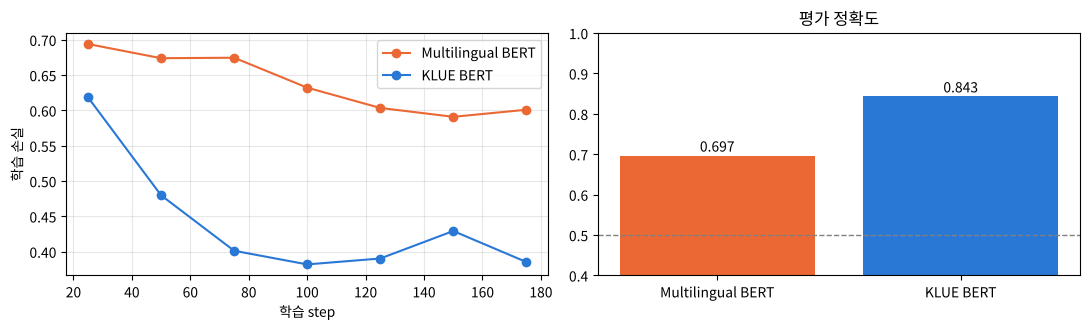

In [14]:
import matplotlib.pyplot as plt
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

logs = {name: [(h['step'], h['loss']) for h in tr.state.log_history if 'loss' in h]
        for name, tr in [('Multilingual BERT', multi_trainer), ('KLUE BERT', klue_trainer)]}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (name, lg), c in zip(logs.items(), ['#eb6834', '#2a78d6']):
    axes[0].plot(*zip(*lg), 'o-', color=c, label=name)
axes[0].set_xlabel('학습 step'); axes[0].set_ylabel('학습 손실'); axes[0].legend(); axes[0].grid(alpha=0.3)
names = list(results)
accs = [results[n]['eval_accuracy'] for n in names]
axes[1].bar(names, accs, color=['#eb6834', '#2a78d6'])
for i, a in enumerate(accs):
    axes[1].text(i, a + 0.01, f'{a:.3f}', ha='center')
axes[1].set_ylim(0.4, 1); axes[1].axhline(0.5, color='gray', ls='--', lw=1); axes[1].set_title('평가 정확도')
plt.tight_layout(); plt.show()

import json
json.dump(logs, open('finetune_logs.json', 'w'))       # 학습 손실 기록 (GIF 그릴 때 사용)

- 같은 BERT-base 구조 · 같은 학습량인데 **한국어 사전으로 사전 학습한 KLUE BERT 가 더 높다** — 원본(GPU · 전체 12만 개 학습)에서도 다국어 **0.848** vs KLUE **0.898**. 데이터가 적을수록 차이가 커진다 — 다국어 모델은 [UNK] 로 지워진 단어(`재밌다 · ㅋㅋ · ㅠㅠ`)를 쓸 수 없고, 한국어를 덜 배운 상태에서 출발하기 때문이다.
- 미세 조정 전(분류층이 무작위)은 0.5 근처 — 학습한 것은 거의 이 분류층과, 그 아래 BERT 가중치의 작은 조정이다.
- CPU 로 3,000개만 학습한 이번 결과는 원본보다 낮다. 데이터가 40배 많으면 더 오른다 — Colab GPU 로 `FULL = True` 실행.

> **📝 고친 부분 (원본 cell 30 · 38 `TrainingArguments`)**
> - `learning_rate=0.0001` → BERT 논문 미세 조정 권장값(5e-5 · 3e-5 · 2e-5) 중 **5e-5** + 처음 10% 워밍업. 1e-4 는 미세 조정에는 큰 편이라 학습이 불안정해지기 쉽다
> - 1 에폭인데 `load_best_model_at_end=True` · `metric_for_best_model` · `save_strategy='epoch'` → 저장 · 다시 불러오기만 늘어난다. 원본 다국어 모델은 다시 불러오면서 '**missing keys … LayerNorm**' 경고가 나왔다(체크포인트 이름 규칙이 다른 경우 LayerNorm 이 초기값으로 바뀔 수 있다) → 에폭이 하나면 `save_strategy='no'` 로 학습 끝난 모델을 그대로 쓰고, 저장은 따로 `save_model()`
> - 모델을 만들 때 `id2label` 을 넣지 않아 저장 후 `{0: 'LABEL_0', 1: 'LABEL_1'}` 로 나왔다 → `id2label={0: 'negative', 1: 'positive'}`
> - 결과 경로가 `/content/drive/MyDrive/sk/…` 로 고정 → 노트북 폴더 아래 `out_*`

## 5. 저장 → 불러오기 → 추론 (교재 p.109)

In [15]:
save_path = 'kor_finetuned_model'
klue_trainer.save_model(save_path)                      # 가중치 · config · 토크나이저
loaded = BertForSequenceClassification.from_pretrained(save_path)
print('불러온 모델 레이블 :', loaded.config.id2label)

check = Trainer(model=loaded, args=TrainingArguments(output_dir='tmp_eval', per_device_eval_batch_size=64, report_to='none'),
                compute_metrics=compute_metrics).evaluate(klue_test)
print(f"불러온 모델 평가 정확도 : {check['eval_accuracy']:.3f} (저장 전과 같음 : {abs(check['eval_accuracy'] - results['KLUE BERT']['eval_accuracy']) < 1e-9})")

불러온 모델 레이블 : {0: 'negative', 1: 'positive'}


{'eval_loss': '0.3635', 'eval_model_preparation_time': '0.0039', 'eval_accuracy': '0.843', 'eval_runtime': '71.86', 'eval_samples_per_second': '27.83', 'eval_steps_per_second': '0.445', 'epoch': 0}
불러온 모델 평가 정확도 : 0.843 (저장 전과 같음 : True)


In [16]:
from transformers import pipeline
my_classifier = pipeline('text-classification', model=save_path, tokenizer=save_path)
for s in ['배우들 연기가 정말 좋았고 마지막 장면에서 눈물이 났다', '시간 아깝다 이런 영화를 왜 만들었는지',
          '기대 안 했는데 의외로 재밌네', '재밌다는 사람들 이해가 안 감']:
    p = my_classifier(s)[0]
    print(f"{p['label']:8s} {p['score']:.3f}  {s}")

positive 0.979  배우들 연기가 정말 좋았고 마지막 장면에서 눈물이 났다


negative 0.972  시간 아깝다 이런 영화를 왜 만들었는지
positive 0.960  기대 안 했는데 의외로 재밌네
negative 0.766  재밌다는 사람들 이해가 안 감


In [17]:
# 마켓컬리 갈비탕 리뷰 200개에 적용 — 직접 미세 조정한 모델 vs 공개 모델(doya/klue-sentiment-nsmc)
for path in ['kurly_reviews.csv', 'data/kurly_reviews.csv']:
    if os.path.exists(path):
        break
kurly = pd.read_csv(path)
mine = my_classifier(kurly['리뷰'].tolist(), truncation=True, max_length=512, batch_size=16)
pub = pipeline('text-classification', model='doya/klue-sentiment-nsmc')(kurly['리뷰'].tolist(), truncation=True, max_length=512, batch_size=16)
kurly['내 모델'] = [p['label'] for p in mine]
kurly['공개 모델'] = ['positive' if p['label'] == 'LABEL_1' else 'negative' for p in pub]
print(pd.crosstab(kurly['내 모델'], kurly['공개 모델']))
print(f"두 모델 일치율 : {(kurly['내 모델'] == kurly['공개 모델']).mean():.1%}")

공개 모델     negative  positive
내 모델                        
negative         1         1
positive         3       195
두 모델 일치율 : 98.0%


- 학습에 쓰지 않은 **새 분야(음식 리뷰)** 에 적용한 추론이다. 정답이 없어서 정확도는 모르고, 두 모델이 얼마나 같은 판단을 하는지만 본다.
- 직접 학습한 모델의 레이블은 `id2label` 덕분에 `positive` · `negative` 로 바로 나온다.

## 정리

| 순서 (교재 p.113) | 코드 |
|---|---|
| 1 데이터 | `read_csv(sep='\t')` → `dropna` → `train_test_split(stratify=…)` |
| 2~3 Dataset | `tokenizer(X, truncation=True, padding='max_length', max_length=분위수+2)` → `ClassificationDataset` |
| 4 모델 | `BertForSequenceClassification.from_pretrained(이름, num_labels=2, id2label=…)` |
| 5~6 Trainer | `TrainingArguments(lr=5e-5, …)` → `Trainer(model, args, train_dataset, eval_dataset, compute_metrics)` |
| 7 학습 | `trainer.train()` |
| 8 평가 | `trainer.evaluate(test_ds)` |
| 저장 · 추론 | `save_model()` → `from_pretrained()` / `pipeline('text-classification', model=경로)` |